# Student Performance Prediction With Regression

The Student Performance Dataset is a dataset designed to examine the factors influencing academic student performance. The dataset consists of 10,000 student records, with each record containing information about various predictors and a performance index. And we'll aim to predict students performance with with regression

In [1]:
import pandas as pd

students = pd.read_csv("Student_performance.csv")
students.head()


,Hours Studied,Previous Scores,Extracurricular Activities,Sleep Hours,Sample Question Papers Practiced,Performance Index
0,7,99,Yes,9,1,91.0
1,4,82,No,4,2,65.0
2,8,51,Yes,7,2,45.0
3,5,52,Yes,5,2,36.0
4,7,75,No,8,5,66.0


In [2]:
students.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 6 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   Hours Studied                     10000 non-null  int64  
 1   Previous Scores                   10000 non-null  int64  
 2   Extracurricular Activities        10000 non-null  str    
 3   Sleep Hours                       10000 non-null  int64  
 4   Sample Question Papers Practiced  10000 non-null  int64  
 5   Performance Index                 10000 non-null  float64
dtypes: float64(1), int64(4), str(1)
memory usage: 493.2 KB


In [3]:
students.describe()

,Hours Studied,Previous Scores,Sleep Hours,Sample Question Papers Practiced,Performance Index
count,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000
mean,4.992900,69.445700,6.530600,4.583300,55.224800
std,2.589309,17.343152,1.695863,2.867348,19.212558
min,1.000000,40.000000,4.000000,0.000000,10.000000
25%,3.000000,54.000000,5.000000,2.000000,40.000000
50%,5.000000,69.000000,7.000000,5.000000,55.000000
75%,7.000000,85.000000,8.000000,7.000000,71.000000
max,9.000000,99.000000,9.000000,9.000000,100.000000


In [4]:
students.isnull().sum()

Hours Studied                       0
Previous Scores                     0
Extracurricular Activities          0
Sleep Hours                         0
Sample Question Papers Practiced    0
Performance Index                   0
dtype: int64

In [5]:
students.duplicated().sum()

np.int64(127)

In [6]:
students[students.duplicated(keep=False)].sort_values(students.columns.tolist())

,Hours Studied,Previous Scores,Extracurricular Activities,Sleep Hours,Sample Question Papers Practiced,Performance Index
6975,1,41,No,7,3,12.0
9966,1,41,No,7,3,12.0
2225,1,42,Yes,9,7,17.0
4986,1,42,Yes,9,7,17.0
2647,1,57,No,8,0,31.0
...,...,...,...,...,...,...
8118,9,86,Yes,6,9,83.0
3482,9,87,No,7,3,88.0
4261,9,87,No,7,3,88.0
8214,9,87,No,7,9,86.0


In [7]:
students = students.drop_duplicates()

In [8]:
students["Extracurricular Activities"] = students["Extracurricular Activities"].map({"Yes": 1, "No": 0})

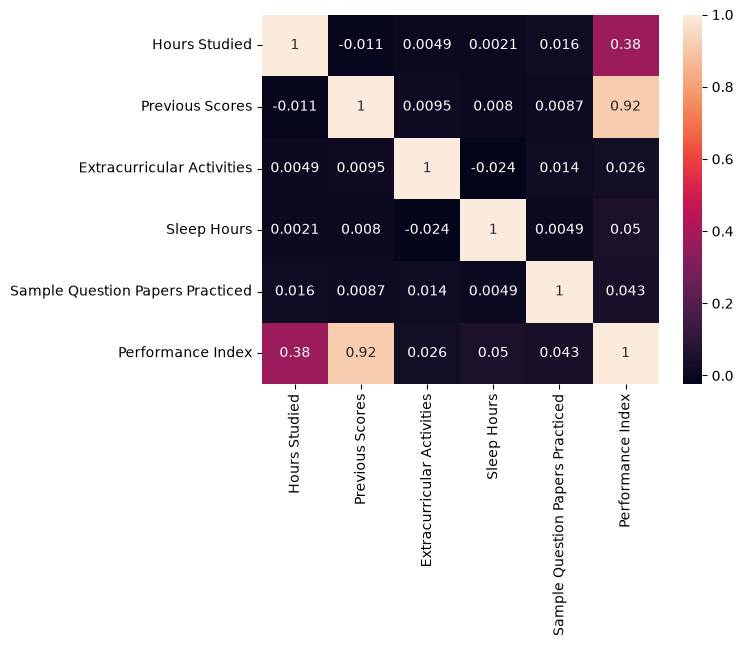

Performance Index                   1.000000
Previous Scores                     0.915135
Hours Studied                       0.375332
Sleep Hours                         0.050352
Sample Question Papers Practiced    0.043436
Extracurricular Activities          0.026075
Name: Performance Index, dtype: float64

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.heatmap(students.corr(), annot=True)
plt.show()
students.corr()["Performance Index"].sort_values(ascending=False)

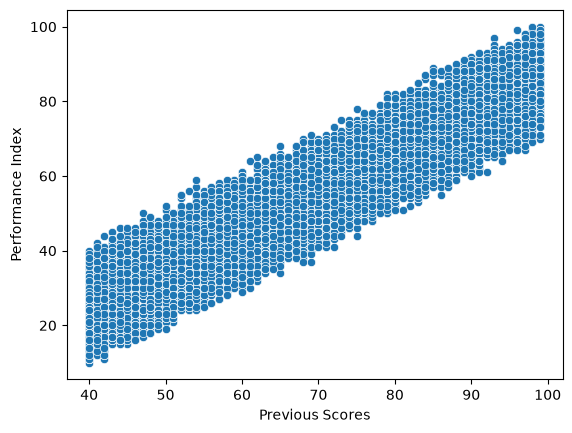

In [10]:
sns.scatterplot(data=students, x="Previous Scores", y="Performance Index")
plt.show()


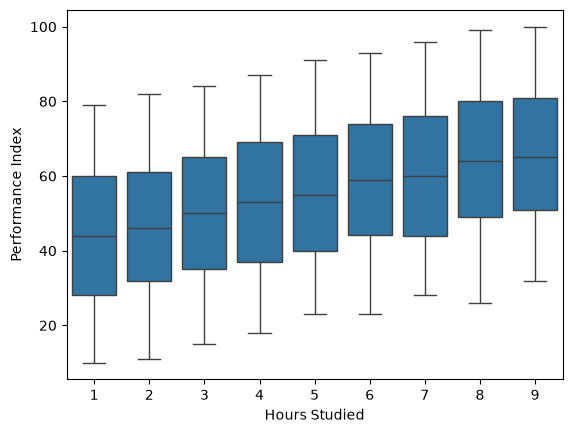

In [11]:
sns.boxplot(data=students, x="Hours Studied", y="Performance Index")
plt.show()

<Axes: xlabel='Sleep Hours', ylabel='Performance Index'>

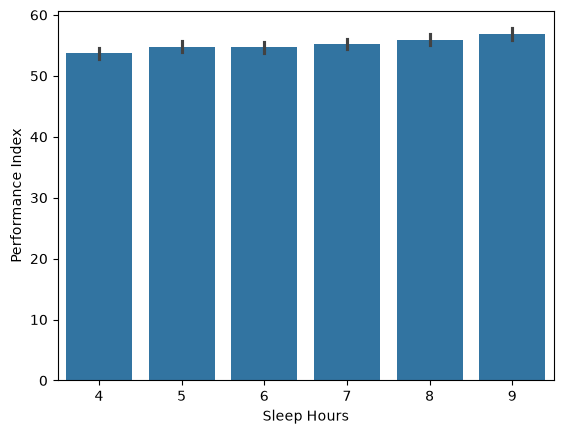

In [12]:
sns.barplot(data=students, x="Sleep Hours", y="Performance Index")

In [13]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score, mean_squared_error

from sklearn.linear_model import (
    LinearRegression, Ridge, Lasso, ElasticNet,
    SGDRegressor, HuberRegressor, RANSACRegressor,
    BayesianRidge, OrthogonalMatchingPursuit,
)
from sklearn.tree import DecisionTreeRegressor, ExtraTreeRegressor
from sklearn.ensemble import (
    RandomForestRegressor, GradientBoostingRegressor,
    HistGradientBoostingRegressor, AdaBoostRegressor,
)
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR
from sklearn.neural_network import MLPRegressor
from xgboost import XGBRegressor
from catboost import CatBoostRegressor

warnings.filterwarnings("ignore")

TREE_MODELS = {
    "Extra Tree", "Decision Tree", "Random Forest", "Gradient Boosting",
    "HistGradientBoosting", "AdaBoost", "XGBoost", "CatBoost",
}
SCALE_Y = {"SGD", "SVR", "MLP"}

def algo_test(x, y):
    x = pd.DataFrame(x).astype(float)
    y = pd.Series(y).astype(float)

    algos = [
        LinearRegression(),
        Ridge(),
        Lasso(max_iter=10000),
        ElasticNet(max_iter=10000),
        SGDRegressor(max_iter=5000, tol=1e-3, random_state=42),
        HuberRegressor(max_iter=500),
        RANSACRegressor(random_state=42),
        BayesianRidge(),
        OrthogonalMatchingPursuit(),
        ExtraTreeRegressor(random_state=42),
        DecisionTreeRegressor(random_state=42),
        RandomForestRegressor(random_state=42, n_jobs=-1),
        GradientBoostingRegressor(random_state=42),
        HistGradientBoostingRegressor(random_state=42),
        AdaBoostRegressor(random_state=42),
        XGBRegressor(verbosity=0, n_jobs=-1, random_state=42),
        CatBoostRegressor(verbose=0, random_state=42),
        KNeighborsRegressor(),
        SVR(),
        MLPRegressor(max_iter=500, hidden_layer_sizes=(64, 32), random_state=42),
    ]
    algo_names = [
        "Linear", "Ridge", "Lasso", "ElasticNet", "SGD", "Huber", "RANSAC",
        "BayesianRidge", "OMP",
        "Extra Tree", "Decision Tree", "Random Forest", "Gradient Boosting",
        "HistGradientBoosting", "AdaBoost", "XGBoost", "CatBoost",
        "KNN", "SVR", "MLP",
    ]

    x_train, x_test, y_train, y_test = train_test_split(
        x, y, test_size=0.2, random_state=42
    )

    results = []
    best = None

    for name, algo in zip(algo_names, algos):
        x_scaler = None
        if name in TREE_MODELS:
            x_tr, x_te = x_train, x_test
        else:
            x_scaler = StandardScaler()
            x_tr = x_scaler.fit_transform(x_train)
            x_te = x_scaler.transform(x_test)

        y_tr = y_train
        y_scaler = None
        if name in SCALE_Y:
            y_scaler = StandardScaler()
            y_tr = y_scaler.fit_transform(y_train.to_numpy().reshape(-1, 1)).ravel()

        preds = algo.fit(x_tr, y_tr).predict(x_te)
        if y_scaler is not None:
            preds = y_scaler.inverse_transform(np.asarray(preds).reshape(-1, 1)).ravel()

        r2 = r2_score(y_test, preds)
        rmse = mean_squared_error(y_test, preds) ** 0.5
        results.append({"Model": name, "R2": r2, "RMSE": rmse})

        if best is None or r2 > best["R2"]:
            best = {
                "name": name,
                "model": algo,
                "x_scaler": x_scaler,
                "y_scaler": y_scaler,
                "pred": preds,
                "y_test": y_test,
                "R2": r2,
                "RMSE": rmse,
            }

    result_df = pd.DataFrame(results).sort_values("R2", ascending=False).reset_index(drop=True)
    print(result_df)

    plt.figure(figsize=(18, 7))
    plt.subplot(1, 2, 1)
    sns.barplot(data=result_df, x="Model", y="R2")
    plt.xticks(rotation=45, ha="right")
    plt.title("R2")
    plt.subplot(1, 2, 2)
    sns.barplot(data=result_df, x="Model", y="RMSE")
    plt.xticks(rotation=45, ha="right")
    plt.title("RMSE")
    plt.tight_layout()
    plt.show()

    return result_df, best

                   Model        R2      RMSE
0                 Linear  0.988430  2.075066
1                 RANSAC  0.988430  2.075066
2          BayesianRidge  0.988430  2.075067
3                  Ridge  0.988430  2.075077
4                  Huber  0.988427  2.075302
5                    SGD  0.988405  2.077295
6                    SVR  0.987790  2.131659
7      Gradient Boosting  0.987705  2.139136
8               CatBoost  0.987626  2.146000
9   HistGradientBoosting  0.987521  2.155068
10                   MLP  0.987413  2.164342
11               XGBoost  0.986231  2.263701
12         Random Forest  0.984875  2.372552
13                 Lasso  0.979239  2.779687
14                   KNN  0.976427  2.961908
15              AdaBoost  0.975989  2.989345
16         Decision Tree  0.975258  3.034488
17            Extra Tree  0.974324  3.091254
18            ElasticNet  0.859091  7.241635
19                   OMP  0.835797  7.817336


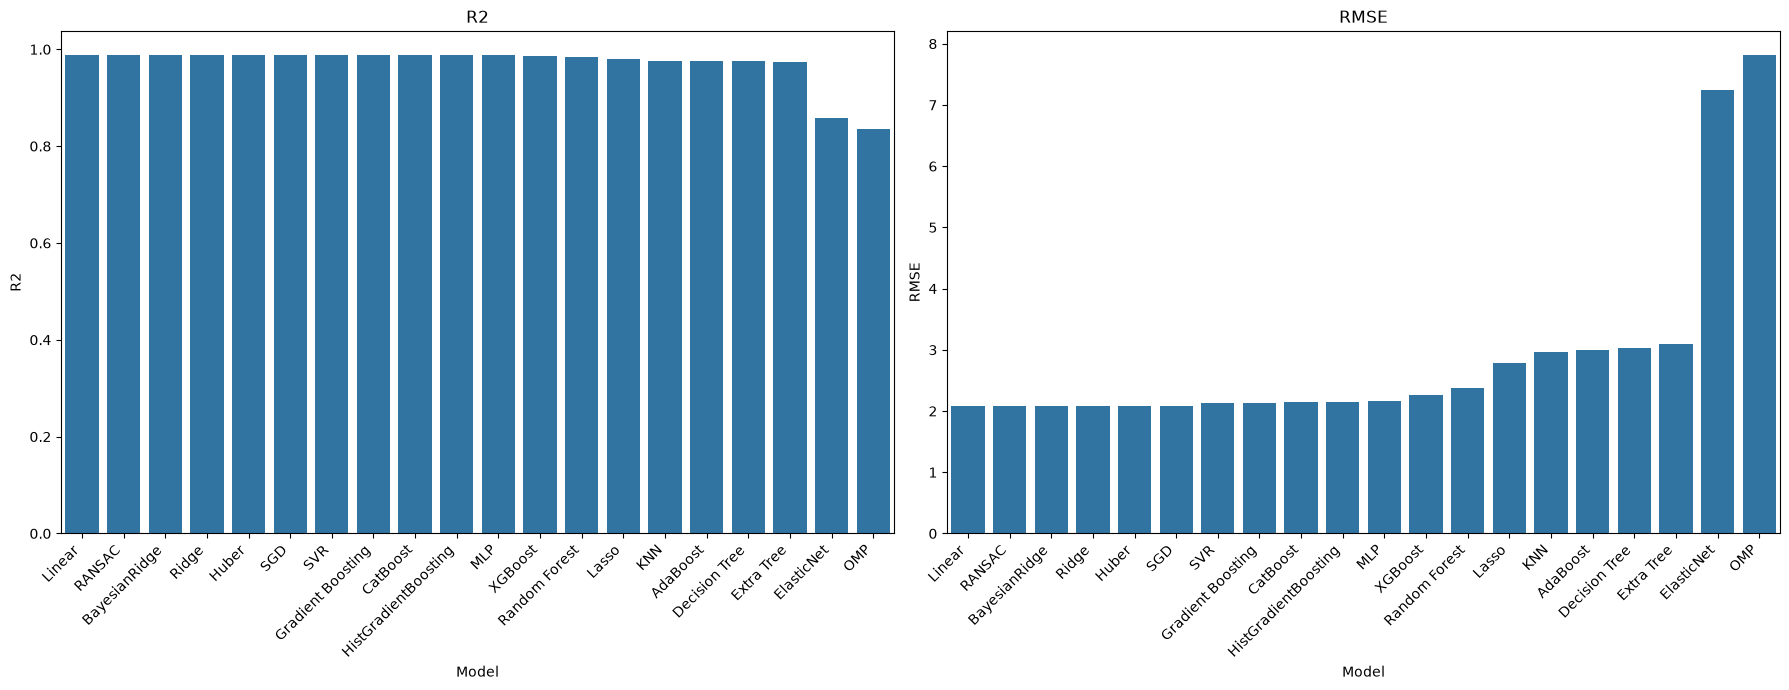

In [14]:
X = students.drop(columns="Performance Index")
y = students["Performance Index"]

result_df, best = algo_test(X, y)

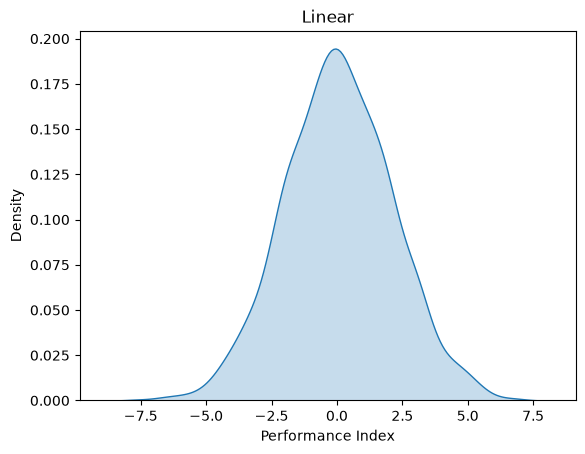

In [15]:
residuals = best["y_test"] - best["pred"]
sns.kdeplot(residuals, fill=True)
plt.title(best["name"])
plt.show()



In [16]:
print(best["name"], best["R2"], best["RMSE"])

if hasattr(best["model"], "coef_"):
    coefs = pd.Series(best["model"].coef_, index=X.columns)
    print(coefs.sort_values(key=abs, ascending=False))


Linear 0.9884301209927054 2.075066490148803
Previous Scores                     17.619931
Hours Studied                        7.373316
Sleep Hours                          0.802138
Sample Question Papers Practiced     0.540053
Extracurricular Activities           0.286906
dtype: float64


In [17]:
import numpy as np
import tensorflow as tf
from tensorflow import keras
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score, mean_squared_error

tf.keras.utils.set_random_seed(42)

x_train, x_test, y_train, y_test = train_test_split(
    X.astype(float), y.astype(float), test_size=0.20, random_state=42
)

x_scaler = StandardScaler()
y_scaler = StandardScaler()
x_tr = x_scaler.fit_transform(x_train)
x_te = x_scaler.transform(x_test)
y_tr = y_scaler.fit_transform(y_train.to_numpy().reshape(-1, 1))

dl = keras.Sequential([
    keras.layers.Input(shape=(x_tr.shape[1],)),
    keras.layers.Dense(64, activation="relu"),
    keras.layers.Dropout(0.2),
    keras.layers.Dense(32, activation="relu"),
    keras.layers.Dense(1),
])
dl.compile(optimizer="adam", loss="mse")
dl.fit(x_tr, y_tr, validation_split=0.2, epochs=80, batch_size=32, callbacks=[keras.callbacks.EarlyStopping(patience=12, restore_best_weights=True)], verbose=0)

pred = y_scaler.inverse_transform(dl.predict(x_te, verbose=0)).ravel()
print("DeepLearning R2  :", r2_score(y_test, pred))
print("DeepLearning RMSE:", mean_squared_error(y_test, pred) ** 0.5)

DeepLearning R2  : 0.9826341340527276
DeepLearning RMSE: 2.54223580220377


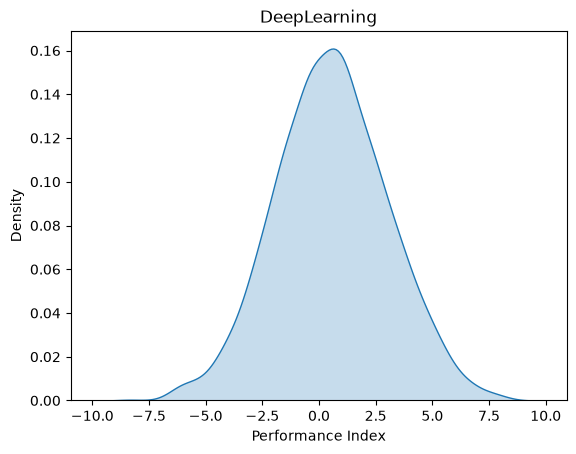

In [19]:
residuals = y_test - pred
sns.kdeplot(residuals, fill=True)
plt.title("DeepLearning")
plt.show()

In [18]:

joblib.dump(best["model"], "Regression3student_performance_model.joblib")

['Regression3student_performance_model.joblib']

# Conclusion 

We uploaded the data do some EDA and analyzes and tried many Machine Learning Algorithims the best result we got was with Linear Regression with 98 R2 score and then trained the data again with deep learning as well and got a raely good result there as well with 98 R2 and then saved the model with joblib